In [4]:
pip install os pandas

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement os (from versions: none)
ERROR: No matching distribution found for os

[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os
import pandas as pd

data_folder = '../data'
data_files = [f for f in os.listdir(data_folder) if f.endswith('.csv')]
data_dict = {}

for file in data_files:
    file_path = os.path.join(data_folder, file)
    df_name = os.path.splitext(file)[0]
    data_dict[df_name] = pd.read_csv(file_path)


In [6]:
for df_name, df in data_dict.items():
    print(f"{df_name}: {df.shape}")

birth_district_sex: (1401, 6)
crime_district: (19152, 6)
gdp_state_real_supply: (1904, 5)
hh_income_district: (318, 5)
population_district: (319200, 7)


In [7]:
for df_name, df in data_dict.items():
    print(f"Head of {df_name}:")
    print(df.head())
    print("\n")


Head of birth_district_sex:
         date  state     district     sex    abs       rate
0  2020-01-01  Johor   Batu Pahat    both   6653  13.432263
1  2020-01-01  Johor   Batu Pahat  female   3236  13.846812
2  2020-01-01  Johor   Batu Pahat    male   3417  13.061927
3  2020-01-01  Johor  Johor Bahru    both  24675  14.419705
4  2020-01-01  Johor  Johor Bahru  female  11954  14.870009


Head of crime_district:
      state district category type        date  crimes
0  Malaysia      All  assault  all  2016-01-01   22327
1  Malaysia      All  assault  all  2017-01-01   21366
2  Malaysia      All  assault  all  2018-01-01   16902
3  Malaysia      All  assault  all  2019-01-01   16489
4  Malaysia      All  assault  all  2020-01-01   13279


Head of gdp_state_real_supply:
  series        date  state sector       value
0    abs  2015-01-01  Johor     p0  110002.221
1    abs  2015-01-01  Johor     p1   15610.314
2    abs  2015-01-01  Johor     p2     475.640
3    abs  2015-01-01  Johor     p3 

In [8]:
import re

for df_name, df in data_dict.items():
    # Create a year column from the first date column found
    date_columns = [col for col in df.columns if re.search(r'\d{4}-\d{2}-\d{2}', str(df[col].iloc[0]))]
    if date_columns:
        df['year'] = pd.to_datetime(df[date_columns[0]]).dt.year
    
    # Drop all date columns
    df.drop(columns=date_columns, inplace=True)


In [9]:
for df_name, df in data_dict.items():
    print(f"Head of {df_name}:")
    print(df.head())
    print("\n")

Head of birth_district_sex:
   state     district     sex    abs       rate  year
0  Johor   Batu Pahat    both   6653  13.432263  2020
1  Johor   Batu Pahat  female   3236  13.846812  2020
2  Johor   Batu Pahat    male   3417  13.061927  2020
3  Johor  Johor Bahru    both  24675  14.419705  2020
4  Johor  Johor Bahru  female  11954  14.870009  2020


Head of crime_district:
      state district category type  crimes  year
0  Malaysia      All  assault  all   22327  2016
1  Malaysia      All  assault  all   21366  2017
2  Malaysia      All  assault  all   16902  2018
3  Malaysia      All  assault  all   16489  2019
4  Malaysia      All  assault  all   13279  2020


Head of gdp_state_real_supply:
  series  state sector       value  year
0    abs  Johor     p0  110002.221  2015
1    abs  Johor     p1   15610.314  2015
2    abs  Johor     p2     475.640  2015
3    abs  Johor     p3   32358.659  2015
4    abs  Johor     p4    7269.160  2015


Head of hh_income_district:
   state     distri

In [10]:
print(len(df))

df = data_dict['crime_district']
dff = df[df['type'] == 'all']
dff = dff[dff['district'] != 'All']
dff = dff[dff['state'] != 'Malaysia']

columns = dff.columns.tolist()
columns.remove('district')
columns.remove('year')

# Group by 'district' and 'year', take the first of every column and sum of 'crimes' column
grouped_dff = dff.groupby(['district', 'year']).agg({col: 'first' if col != 'crimes' and col != 'year' else 'sum' for col in columns}).reset_index()

del grouped_dff['category'], grouped_dff['type']

massaged_dict = {}
massaged_dict['crime_district'] = grouped_dff

print(len(grouped_dff))

319200
1248


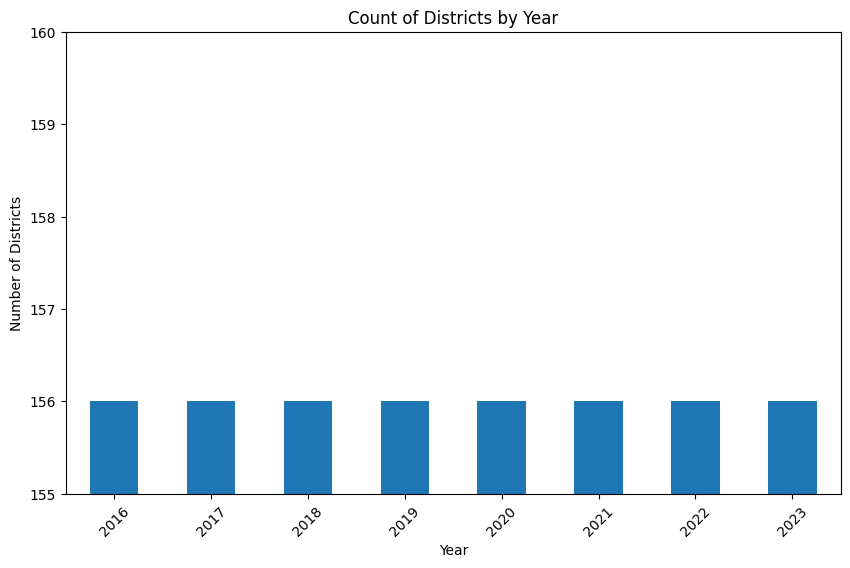

In [11]:
import matplotlib.pyplot as plt

# Count the number of districts by year
district_counts = grouped_dff.groupby('year')['district'].nunique()

# Plot the bar chart
plt.figure(figsize=(10, 6))
district_counts.plot(kind='bar')
plt.title('Count of Districts by Year')
plt.xlabel('Year')
plt.ylabel('Number of Districts')
plt.ylim(155,160)
plt.xticks(rotation=45)
plt.show()



In [12]:
# Clean the 'district' column
grouped_dff['district'] = grouped_dff['district'].replace({
    'Sg. Buloh': 'Sungai Buloh',
    'Cameron Highland': 'Cameron Highlands',
    'Bandar Bharu': 'Bandar Baharu'
})

In [13]:
grouped_dff.district.value_counts()[grouped_dff.district.value_counts() < 8].index.tolist()

[]

In [14]:
# Districts has been cleaned

In [15]:
# Find the districts that are not shared across all data
all_districts = set()
shared_districts = None
districts_not_in_dfs = {}
crime_districts = set()
other_districts = set()

# Separate districts in crime data and other data
for key, df in data_dict.items():
    if 'district' in df.columns:
        districts = set(df['district'].unique())
        all_districts.update(districts)
        if key == 'crime':
            crime_districts = districts
        else:
            other_districts.update(districts)
        if shared_districts is None:
            shared_districts = districts
        else:
            shared_districts &= districts
    else:
        print(f"Dataframe '{key}' does not have a 'district' column")

if shared_districts is not None:
    not_shared_districts = all_districts - shared_districts
else:
    not_shared_districts = all_districts

# Identify which dataframes don't have the not shared districts
for district in not_shared_districts:
    districts_not_in_dfs[district] = []
    for key, df in data_dict.items():
        if 'district' in df.columns and district not in df['district'].unique():
            districts_not_in_dfs[district].append(key)

# Separate reporting
crime_not_in_others = crime_districts - other_districts
others_not_in_crime = other_districts - crime_districts
unique_districts = not_shared_districts

# Adjust the reporting based on the instruction
all_not_in_others = {district for district, dfs in districts_not_in_dfs.items() if set(dfs) == {'birth_district_sex', 'hh_income_district', 'population_district'}}
in_four_not_crime = {district for district, dfs in districts_not_in_dfs.items() if len(dfs) == 4 and 'crime' not in dfs}

# Print the reports
print(f"Districts in crime data but not in others ({len(crime_not_in_others)}): {', '.join(crime_not_in_others)}")

print(f"Districts in other data but not in crime ({len(others_not_in_crime)}): {', '.join(others_not_in_crime)}")

print(f"Districts not shared across all data ({len(unique_districts)}):")
for district, dfs in districts_not_in_dfs.items():
    print(f"{district}: not in {', '.join(dfs)}")

print(f"Districts not in birth_district_sex, hh_income_district, population_district ({len(all_not_in_others)}): {', '.join(all_not_in_others)}")

print(f"Districts in 4 datasets but not in crime ({len(in_four_not_crime)}): {', '.join(in_four_not_crime)}")


Dataframe 'gdp_state_real_supply' does not have a 'district' column
Districts in crime data but not in others (0): 
Districts in other data but not in crime (208): Rompin, Kluang, Kota Kinabalu, Semporna, Kota Setar, Muallim, Kunak, Pusa, Bera, Ipoh, Port Dickson, Papar, Sg. Buloh, Kuala Terengganu, Padang Besar, Hulu Terengganu, Lipis, Tanjung Manis, Selangau, Sepang, Tebedu, Kinta, Larut dan Matang, Kuala Selangor, Tenom, Tapah, Kota Kinabatangan, Kuala Penyu, Kuala Muda, Keningau, Hulu Selangor, Lubok Antu, Marang, Sp Tengah, Machang, Beluru, Sri Aman, Kecil Lojing, Bachok, Pasir Puteh, Saratok, Kajang, Pontian, Pekan, Kubang Pasu, Kuching, Kerian, Jelebu, Sabak Bernam, Johor Bahru, Lundu, Klang Utara, Yan, Kuala Nerus, Pitas, Sungai Siput, Samarahan, Gombak, Belaga, Padang Terap, Ampang Jaya, Seberang Perai Utara, Tambunan, Brickfields, Petaling Jaya, Tanjong Malim, Mersing, W.P. Kuala Lumpur, Johor Bahru Selatan, Jempol, Kampar, Kulai, Kemaman, Besut, Penampang, Putatan, Langkawi,

In [16]:
# Report how many districts are consistent across all data in data_dict
if shared_districts is not None:
    consistent_districts_count = len(shared_districts)
else:
    consistent_districts_count = 0

print(f"Number of districts consistent across all data: {consistent_districts_count}")


Number of districts consistent across all data: 116


In [17]:
# Assuming 'crime' is the key for the crime dataframe in grouped_dff
if 'crime' in grouped_dff:
    massaged_crime_df = grouped_dff['crime']
    print("Massaged Crime DataFrame:")
    print(massaged_crime_df)
else:
    print("Crime data is not available in the grouped data.")



Crime data is not available in the grouped data.
